# Import packages

In [100]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import re
!python -m spacy download en_core_web_sm

import warnings
warnings.filterwarnings('ignore')

from nltk.stem.snowball import SnowballStemmer

from wordcloud import WordCloud, STOPWORDS
from nltk.corpus import stopwords
import nltk
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
nltk.download("stopwords")

import spacy
import scipy
import datasets
import jupyter
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from collections import Counter
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.datasets import make_classification
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 28.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Importar DATA SET para entrenamiento y test

In [ ]:
from numpy.__config__ import show
url_test = "https://drive.google.com/uc?export=download&id=18hrrgrXT6469bdOwSRhSqQvtKdcVPpYq"
df_test = pd.read_csv(url_test)
test_raw = df_test.copy()

url = "https://drive.google.com/uc?export=download&id=1TSlFi4d7Nu4K-FW1QFaR3MEe2cahfxxj"
df_train = pd.read_csv(url)

##Visualizamos DataSet Train
print("Visualización DataSet_Train")
train_raw = df_train.copy()
df_train['longitud'] = [len(x) for x in df['text']]
df_train.head(10)

Visualización DataSet_Train


,text,label,longitud
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech,182
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech,193
2,Radio Outage Grounds West Coast Flights. Airpo...,Business,209
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech,276
4,Custis Takes Control. Family and Tony Robbins ...,Sports,175
5,CA execs can keep bonuses--for now. Computer A...,Sci_Tech,199
6,"WorldCom, Microsoft cases before EU court. Two...",Business,206
7,EU Court Overturns Bar on Merger (Reuters). Re...,Business,243
8,Homer-happy Mariners end skid. A four-pitch se...,Sports,206
9,Philip Morris lab discovered passive smoking r...,Sci_Tech,265


In [ ]:
##Visualizamos DataSet Test
print("Visualización DataSet_Test")
test_raw = df_test.copy()
df_test['longitud'] = [len(x) for x in df_test['text']]
df_test.head(10)

Visualización DataSet_Test


,text,label,longitud
0,BSkyB sees profits rise after strong subscribe...,World,252
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,Business,442
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",Sports,140
3,"Hackers, spoofers and malware--oh my!. IE expl...",Sci_Tech,142
4,Ravens #39; Ogden could miss Week 8. Baltimore...,Sports,240
5,"Giants win 6th straight, but Schmidt is injure...",Sports,228
6,IBM #39;s New eServer Supports AMD Dual-Core. ...,Sci_Tech,251
7,Producer sues for Rings profits. Hollywood pro...,World,130
8,Techs lead gains on Wall Street. Shares surged...,Business,234
9,Will Bills be more receptive?. FOXBOROUGH -- H...,Sports,147


In [ ]:
##Información DataSet Train
print("Información DataSet_Train")
df_train.info()

Informacin DataSet_Train
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      8000 non-null   object
 1   label     8000 non-null   object
 2   longitud  8000 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 187.6+ KB


In [ ]:
##Información DataSet Test
print("Información DataSet_Test")
df_test.info()

Información DataSet_Test
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      2000 non-null   object
 1   label     2000 non-null   object
 2   longitud  2000 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 47.0+ KB


In [ ]:
df_train.duplicated().sum()

np.int64(0)

In [ ]:
df_test.duplicated().sum()

np.int64(0)

In [ ]:
##Descripción DataSet Train
print("Descripción DataSet_Train")
df_train.describe(include="all").T

Descripción DataSet_Train


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
text,8000,8000,"Red Hat Appoints New CFO. September 2, 2004 --...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,8000,4,Sci_Tech,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitud,8000.0,NaN,NaN,NaN,236.71775,64.921044,100.0,196.0,232.0,266.0,995.0


In [ ]:
##Descripción DataSet Test
print("Descripción DataSet_Test")
df_test.describe(include="all").T

Descripción DataSet_Test


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
text,2000,2000,BSkyB sees profits rise after strong subscribe...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,2000,4,World,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitud,2000.0,NaN,NaN,NaN,234.9145,61.881207,101.0,198.0,233.0,264.0,881.0


In [ ]:
##Contabilización Label DataSet Train
print("Contabilización Label DataSet_Train")
df_train.label.value_counts()


Contabilización Label DataSet_Train


,count
label,
Sci_Tech,2000
Business,2000
Sports,2000
World,2000


In [ ]:
##Contabilización Label DataSet Test
print("Contabilización Label DataSet_Test")
df_test.label.value_counts()

Contabilización Label DataSet_Test


,count
label,
World,500
Business,500
Sports,500
Sci_Tech,500


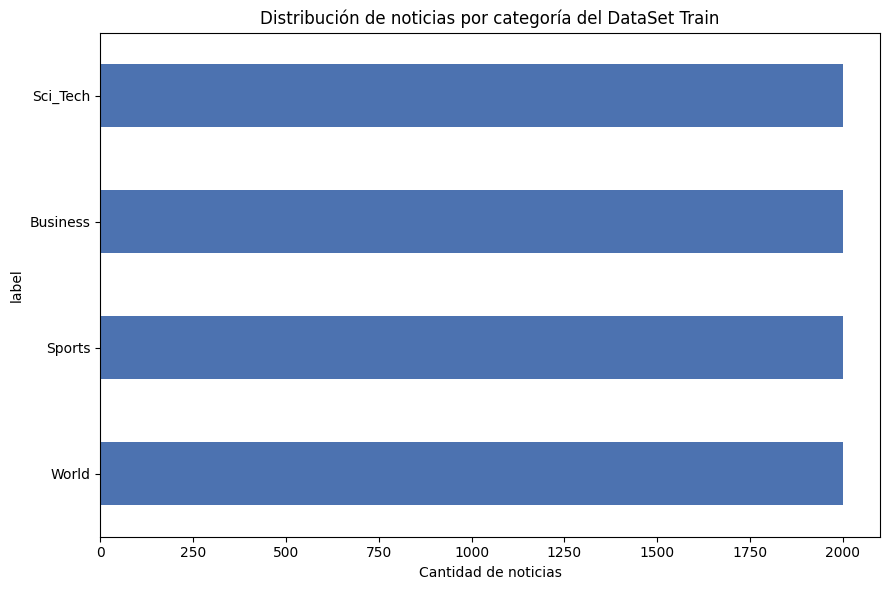

label
Sci_Tech    25.0
Business    25.0
Sports      25.0
World       25.0
Name: proportion, dtype: float64


In [ ]:
##Distribución de Label DataSet Test
df_train['label'].value_counts().plot(kind='barh', color='#4C72B0', figsize=(9,6))
plt.gca().invert_yaxis()
plt.xlabel("Cantidad de noticias")
plt.title("Distribución de noticias por categoría del DataSet Train")
plt.tight_layout()
plt.show()
# Resumen porcentual
print(df_train['label'].value_counts(normalize=True) * 100)

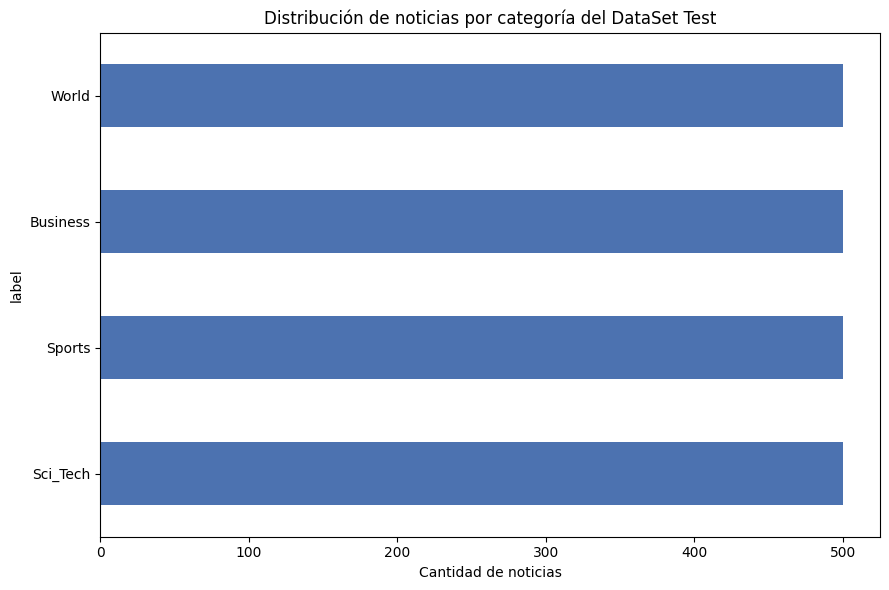

label
World       25.0
Business    25.0
Sports      25.0
Sci_Tech    25.0
Name: proportion, dtype: float64


In [ ]:
##Distribución de Label DataSet Train
df_test['label'].value_counts().plot(kind='barh', color='#4C72B0', figsize=(9,6))
plt.gca().invert_yaxis()
plt.xlabel("Cantidad de noticias")
plt.title("Distribución de noticias por categoría del DataSet Test")
plt.tight_layout()
plt.show()
# Resumen porcentual
print(df_test['label'].value_counts(normalize=True) * 100)

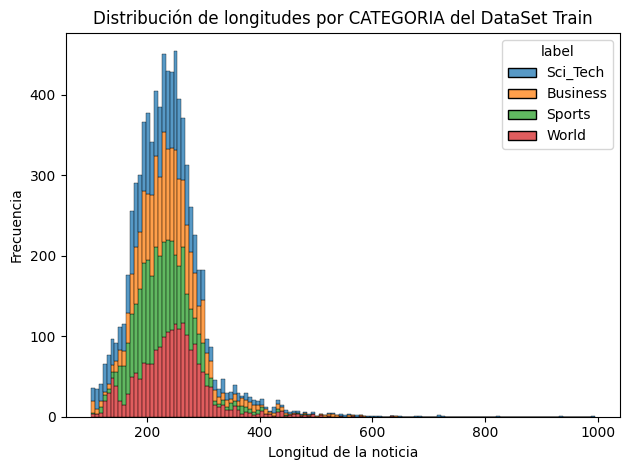

In [ ]:
#Distribucion de los datos DataSet Train
df2 = df_train.copy()
df2['longitud'] = df2['text'].apply(len)

# Histograma apilado por CATEGORIA
sns.histplot(data=df2, x='longitud', hue='label', multiple='stack')

plt.title('Distribución de longitudes por CATEGORIA del DataSet Train')
plt.xlabel('Longitud de la noticia')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

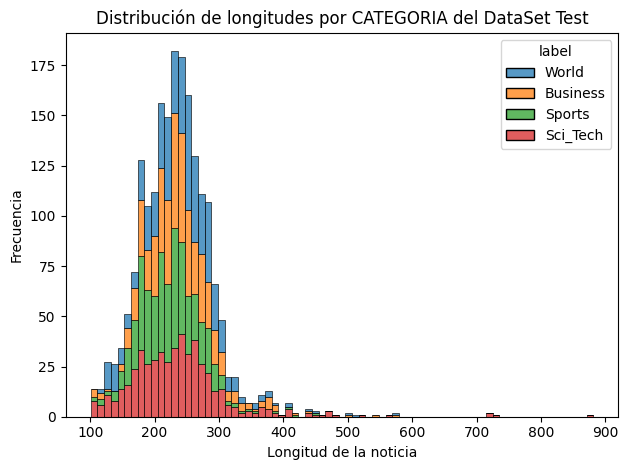

In [ ]:
#Distribucion de los datos DataSet Test
df3 = df_test.copy()
df3['longitud'] = df3['text'].apply(len)

# Histograma apilado por CATEGORIA
sns.histplot(data=df3, x='longitud', hue='label', multiple='stack')

plt.title('Distribución de longitudes por CATEGORIA del DataSet Test')
plt.xlabel('Longitud de la noticia')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

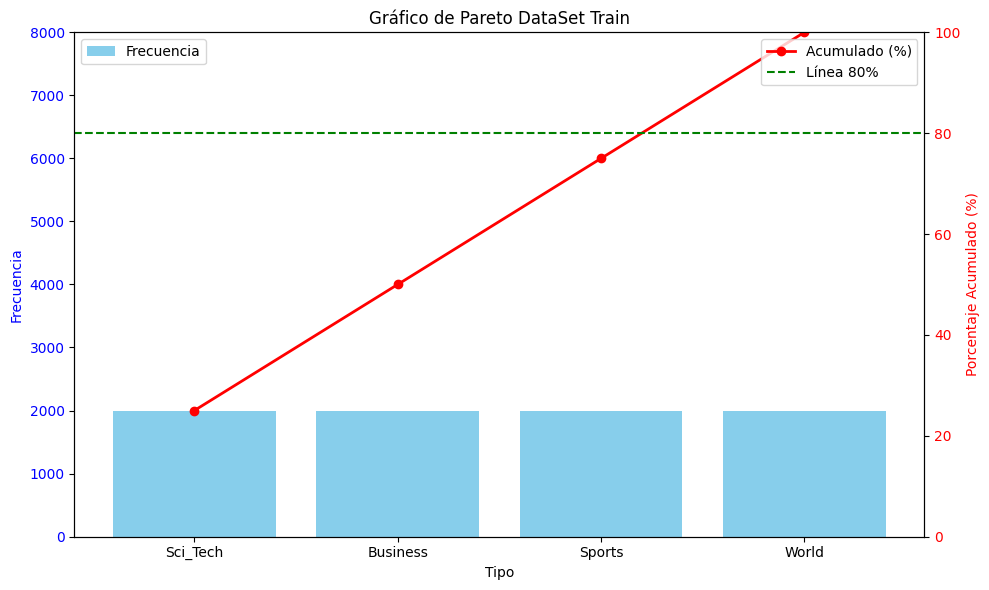

Porcentaje acumulado DataSet Train


,Frecuencia,Porcentaje Acumulado (%)
label,,
Sci_Tech,2000,25.0
Business,2000,50.0
Sports,2000,75.0
World,2000,100.0


In [ ]:
#Analisis de Paretto y Acumulado Data Set Train
# Ordenar de mayor a menor
type_counts = df_train['label'].value_counts()
type_counts = type_counts.sort_values(ascending=False)

# Calcular el porcentaje acumulado y el total
total_records = type_counts.sum()
cumulative_percentage = type_counts.cumsum() / total_records * 100

# Crear la figura y el primer eje (Frecuencia)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Dibujar barras en el primer eje
bars = ax1.bar(type_counts.index, type_counts, color='skyblue', label='Frecuencia')
ax1.set_xlabel('Tipo')
ax1.set_ylabel('Frecuencia', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0, total_records) # Sincronizado para terminar exactamente en el total (8000)

# Crear el segundo eje (Porcentaje Acumulado)
ax2 = ax1.twinx()
line = ax2.plot(cumulative_percentage.index, cumulative_percentage, color='red', marker='o', linewidth=2, label='Acumulado (%)')
ax2.set_ylabel('Porcentaje Acumulado (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 100) # Sincronizado exactamente hasta 100%

# Añadir la línea del 80%
line_80 = ax2.axhline(y=80, color='green', linestyle='--', label='Línea 80%')

# Unificar las leyendas de ambos ejes
ax1.legend(bars, ['Frecuencia'], loc='upper left')
ax2.legend(line + [line_80], ['Acumulado (%)', 'Línea 80%'], loc='upper right')

plt.title('Gráfico de Pareto DataSet Train')
plt.tight_layout()
plt.show()

print("Porcentaje acumulado DataSet Train")
# Mostrar los resultados en formato tabular
pareto_table = pd.DataFrame({
    'Frecuencia': type_counts,
    'Porcentaje Acumulado (%)': cumulative_percentage
})
pareto_table

En nuestro DataSet de Entrenamiento o Train, dado que la distribucion de noticias por categoria es 2000 para cada una de de las cuatro categorias, observamos que se encuentra perfectamente balanceado y esto se refleja en el grafico de Pareto.


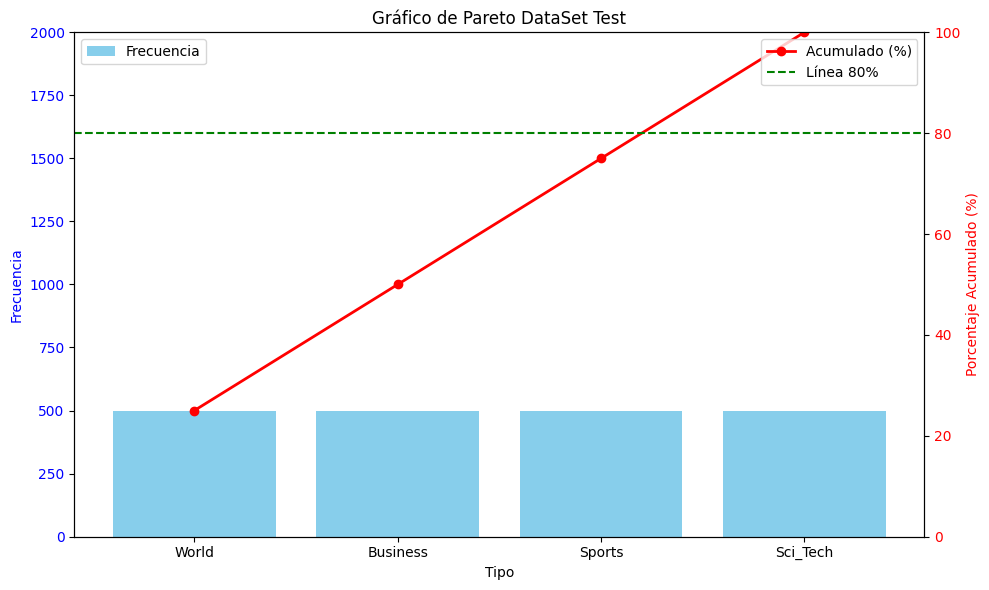

Porcentaje acumulado DataSet Test


,Frecuencia,Porcentaje Acumulado (%)
label,,
World,500,25.0
Business,500,50.0
Sports,500,75.0
Sci_Tech,500,100.0


In [ ]:
#Analisis de Paretto y Acumulado Data Set Test
# Ordenar de mayor a menor
type_counts = df_test['label'].value_counts()
type_counts = type_counts.sort_values(ascending=False)

# Calcular el porcentaje acumulado y el total
total_records = type_counts.sum()
cumulative_percentage = type_counts.cumsum() / total_records * 100

# Crear la figura y el primer eje (Frecuencia)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Dibujar barras en el primer eje
bars = ax1.bar(type_counts.index, type_counts, color='skyblue', label='Frecuencia')
ax1.set_xlabel('Tipo')
ax1.set_ylabel('Frecuencia', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0, total_records) # Sincronizado para terminar exactamente en el total (8000)

# Crear el segundo eje (Porcentaje Acumulado)
ax2 = ax1.twinx()
line = ax2.plot(cumulative_percentage.index, cumulative_percentage, color='red', marker='o', linewidth=2, label='Acumulado (%)')
ax2.set_ylabel('Porcentaje Acumulado (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 100) # Sincronizado exactamente hasta 100%

# Añadir la línea del 80%
line_80 = ax2.axhline(y=80, color='green', linestyle='--', label='Línea 80%')

# Unificar las leyendas de ambos ejes
ax1.legend(bars, ['Frecuencia'], loc='upper left')
ax2.legend(line + [line_80], ['Acumulado (%)', 'Línea 80%'], loc='upper right')

plt.title('Gráfico de Pareto DataSet Test')
plt.tight_layout()
plt.show()

print("Porcentaje acumulado DataSet Test")
# Mostrar los resultados en formato tabular
pareto_table = pd.DataFrame({
    'Frecuencia': type_counts,
    'Porcentaje Acumulado (%)': cumulative_percentage
})
pareto_table


En nuestro DataSet de Test, dado que la distribucion de noticias por categoria es 500 para cada una de de las cuatro categorias, observamos que se encuentra perfectamente balanceado y esto se refleja en el grafico de Pareto.


## Limpienza y Tokenizacion



Limpieza REGEX Data Set Train

In [ ]:
# Instalar e importar la librería contractions para resolver las contracciones en inglés
!pip install -q contractions
import contractions

# Definir la lista de stopwords (palabras vacías)
sw = set(stopwords.words('english'))

def clean_text(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = contractions.fix(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"#\w+", " ", text)
    text = re.sub(r"[^\wáéíóúñÁÉÍÓÚÑüÜ\s]", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

def tokenize(text):
    return [w for w in text.split() if w not in sw and len(w) > 2]

print("Limpieza REGEX Data Set Train")

df_train["clean"] = df_train["text"].apply(clean_text)
df_train["tokens"] = df_train["clean"].apply(tokenize)
df_train[["text", "clean", "tokens"]].head(10)

Limpieza REGEX Data Set Train


,text,clean,tokens
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september web host in...,"[red, hat, appoints, new, cfo, september, web,..."
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roaming deal sprint and ...,"[sprint, sbc, hotspot, roaming, deal, sprint, ..."
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...,"[radio, outage, grounds, west, coast, flights,..."
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuits to strike net pirates holly...,"[hollywood, lawsuits, strike, net, pirates, ho..."
4,Custis Takes Control. Family and Tony Robbins ...,custis takes control family and tony robbins h...,"[custis, takes, control, family, tony, robbins..."
5,CA execs can keep bonuses--for now. Computer A...,ca execs can keep bonuses for now computer ass...,"[execs, keep, bonuses, computer, associates, i..."
6,"WorldCom, Microsoft cases before EU court. Two...",worldcom microsoft cases before eu court two o...,"[worldcom, microsoft, cases, court, two, europ..."
7,EU Court Overturns Bar on Merger (Reuters). Re...,eu court overturns bar on merger reuters reute...,"[court, overturns, bar, merger, reuters, reute..."
8,Homer-happy Mariners end skid. A four-pitch se...,homer happy mariners end skid a four pitch seq...,"[homer, happy, mariners, end, skid, four, pitc..."
9,Philip Morris lab discovered passive smoking r...,philip morris lab discovered passive smoking r...,"[philip, morris, lab, discovered, passive, smo..."


Limpieza REGEX Data Set Test

In [ ]:
# Instalar e importar la librería contractions para resolver las contracciones en inglés
!pip install -q contractions
import contractions

# Definir la lista de stopwords (palabras vacías)
sw = set(stopwords.words('english'))

def clean_text(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = contractions.fix(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"#\w+", " ", text)
    text = re.sub(r"[^\wáéíóúñÁÉÍÓÚÑüÜ\s]", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

def tokenize(text):
    return [w for w in text.split() if w not in sw and len(w) > 2]

print("Limpieza REGEX Data Set Test")
df_test["clean"] = df_test["text"].apply(clean_text)
df_test["tokens"] = df_test["clean"].apply(tokenize)
df_test[["text", "clean", "tokens"]].head(10)

Limpieza REGEX Data Set Test


,text,clean,tokens
0,BSkyB sees profits rise after strong subscribe...,bskyb sees profits rise after strong subscribe...,"[bskyb, sees, profits, rise, strong, subscribe..."
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,before the bell rouse co shares jump lt a href...,"[bell, rouse, shares, jump, href, target, stoc..."
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",minutemen ko d by dukes harrisonburg va opposi...,"[minutemen, dukes, harrisonburg, opposing, run..."
3,"Hackers, spoofers and malware--oh my!. IE expl...",hackers spoofers and malware oh my ie exploit ...,"[hackers, spoofers, malware, exploit, code, co..."
4,Ravens #39; Ogden could miss Week 8. Baltimore...,ravens ogden could miss week baltimore md spor...,"[ravens, ogden, could, miss, week, baltimore, ..."
5,"Giants win 6th straight, but Schmidt is injure...",giants win th straight but schmidt is injured ...,"[giants, win, straight, schmidt, injured, san,..."
6,IBM #39;s New eServer Supports AMD Dual-Core. ...,ibm s new eserver supports amd dual core ibm q...,"[ibm, new, eserver, supports, amd, dual, core,..."
7,Producer sues for Rings profits. Hollywood pro...,producer sues for rings profits hollywood prod...,"[producer, sues, rings, profits, hollywood, pr..."
8,Techs lead gains on Wall Street. Shares surged...,techs lead gains on wall street shares surged ...,"[techs, lead, gains, wall, street, shares, sur..."
9,Will Bills be more receptive?. FOXBOROUGH -- H...,will bills be more receptive foxborough hello ...,"[bills, receptive, foxborough, hello, mike, mu..."


Lematizacion DataSet Train

In [ ]:
def normalize_with_spacy(text: str) -> str:
    """
    Normalización léxica: Casing + Lemmatización.
    """
    # Convertir a minúsculas
    text = text.lower()
    return text

# Usar el modelo en inglés "en_core_web_sm" ya que nuestro dataset está en inglés
nlp = spacy.load("en_core_web_sm", disable=["parser"])

lemmas_all = []
entities_all = []
docs_lemmas = []

# Usamos la columna "text"
for doc in nlp.pipe(df_train["text"].astype(str).tolist(), batch_size=50):
    lemmas = []
    for t in doc:
        if t.is_stop or t.is_punct or t.is_space or not t.is_alpha:
            continue
        lemma = t.lemma_.lower().split()[0]
        if len(lemma) > 2 and lemma not in sw:
            lemmas.append(lemma)
    lemmas_all.extend(lemmas)
    docs_lemmas.append(" ".join(lemmas))
    for ent in doc.ents:
        entities_all.append((ent.text.strip(), ent.label_))

df_train["lemmas_text"] = docs_lemmas
print("Lematización DataSet Train")
df_train[["text", "lemmas_text"]].head(8)

Lematización DataSet Train


,text,lemmas_text
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september web host in...
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc hotspot roaming deal sprint sbc com...
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuit strike net pirate hollywood ...
4,Custis Takes Control. Family and Tony Robbins ...,custis take control family tony robbins mature...
5,CA execs can keep bonuses--for now. Computer A...,exec bonus computer associates international s...
6,"WorldCom, Microsoft cases before EU court. Two...",worldcom microsoft case court european union l...
7,EU Court Overturns Bar on Merger (Reuters). Re...,court overturns bar merger reuters reuters eur...


In [ ]:
lemma_freq = Counter(lemmas_all).most_common(20)
pd.DataFrame(lemma_freq, columns=["lema", "frecuencia"])

,lema,frecuencia
0,say,1811
1,new,1431
2,reuters,1122
3,year,962
4,company,644
5,world,608
6,win,573
7,report,540
8,oil,519
9,monday,517


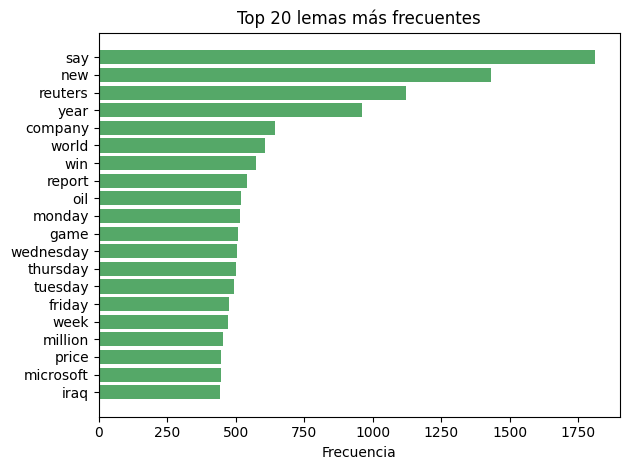

In [ ]:
words, freqs = zip(*lemma_freq)
plt.barh(words[::-1], freqs[::-1], color="#55A868")
plt.xlabel("Frecuencia")
plt.title("Top 20 lemas más frecuentes")
plt.tight_layout()
plt.show()

Percentil 95 (max_len sugerido): 35


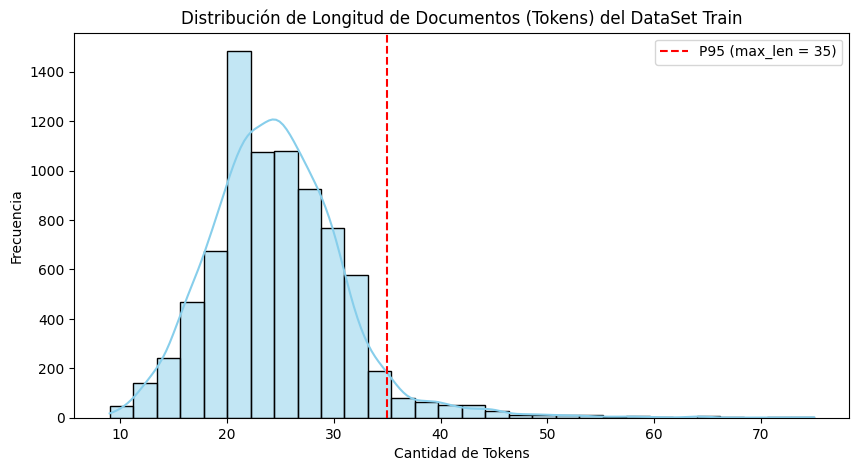

In [ ]:

import seaborn as sns

# Calculamos la longitud en cantidad de tokens por documento utilizando la columna procesada
df_train['token_count'] = df_train['tokens'].apply(len)

# Cálculo del percentil 95
p95 = int(np.percentile(df_train['token_count'], 95))
print(f"Percentil 95 (max_len sugerido): {p95}")

# Histograma de distribución de tokens
plt.figure(figsize=(10, 5))
sns.histplot(df_train['token_count'], kde=True, bins=30, color='skyblue')
plt.axvline(p95, color='red', linestyle='--', label=f'P95 (max_len = {p95})')
plt.title('Distribución de Longitud de Documentos (Tokens) del DataSet Train')
plt.xlabel('Cantidad de Tokens')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

Lematizacion DataSet Test

In [ ]:
def normalize_with_spacy(text: str) -> str:
    """
    Normalización léxica: Casing + Lemmatización.
    """
    # Convertir a minúsculas
    text = text.lower()
    return text

# Usar el modelo en inglés "en_core_web_sm" ya que nuestro dataset está en inglés
nlp = spacy.load("en_core_web_sm", disable=["parser"])

lemmas_all = []
entities_all = []
docs_lemmas = []

# Usamos la columna "text"
for doc in nlp.pipe(df_test["text"].astype(str).tolist(), batch_size=50):
    lemmas = []
    for t in doc:
        if t.is_stop or t.is_punct or t.is_space or not t.is_alpha:
            continue
        lemma = t.lemma_.lower().split()[0]
        if len(lemma) > 2 and lemma not in sw:
            lemmas.append(lemma)
    lemmas_all.extend(lemmas)
    docs_lemmas.append(" ".join(lemmas))
    for ent in doc.ents:
        entities_all.append((ent.text.strip(), ent.label_))

df_test["lemmas_text"] = docs_lemmas
print("Lematización DataSet Test")
df_test[["text", "lemmas_text"]].head(8)

Lematización DataSet Test


,text,lemmas_text
0,BSkyB sees profits rise after strong subscribe...,bskyb see profit rise strong subscriber growth...
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,bell rouse share jump quickinfo jump bell gene...
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",minutemen duke harrisonburg oppose run back be...
3,"Hackers, spoofers and malware--oh my!. IE expl...",hacker spoofer malware exploit code boost risk...
4,Ravens #39; Ogden could miss Week 8. Baltimore...,ravens ogden miss week baltimore sports networ...
5,"Giants win 6th straight, but Schmidt is injure...",giant win straight schmidt injure san francisc...
6,IBM #39;s New eServer Supports AMD Dual-Core. ...,ibm new eserver supports amd dual core ibm quo...
7,Producer sues for Rings profits. Hollywood pro...,producer sue ring profit hollywood producer sa...


In [ ]:
lemma_freq = Counter(lemmas_all).most_common(20)
pd.DataFrame(lemma_freq, columns=["lema", "frecuencia"])

,lema,frecuencia
0,say,463
1,new,339
2,reuters,284
3,year,267
4,company,182
5,win,163
6,world,152
7,oil,145
8,tuesday,137
9,thursday,130


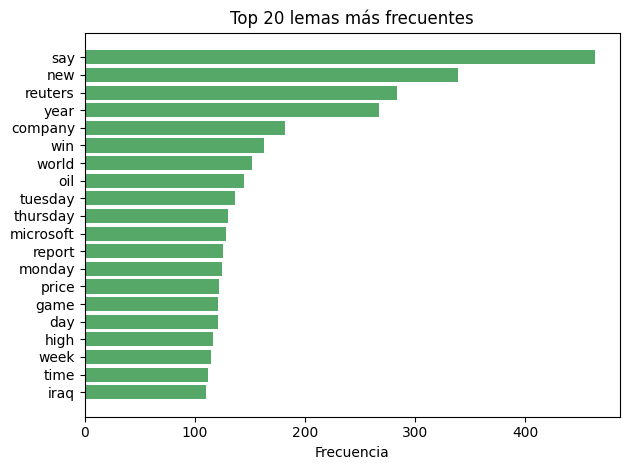

In [ ]:
words, freqs = zip(*lemma_freq)
plt.barh(words[::-1], freqs[::-1], color="#55A868")
plt.xlabel("Frecuencia")
plt.title("Top 20 lemas más frecuentes")
plt.tight_layout()
plt.show()

Percentil 95 (max_len sugerido): 34


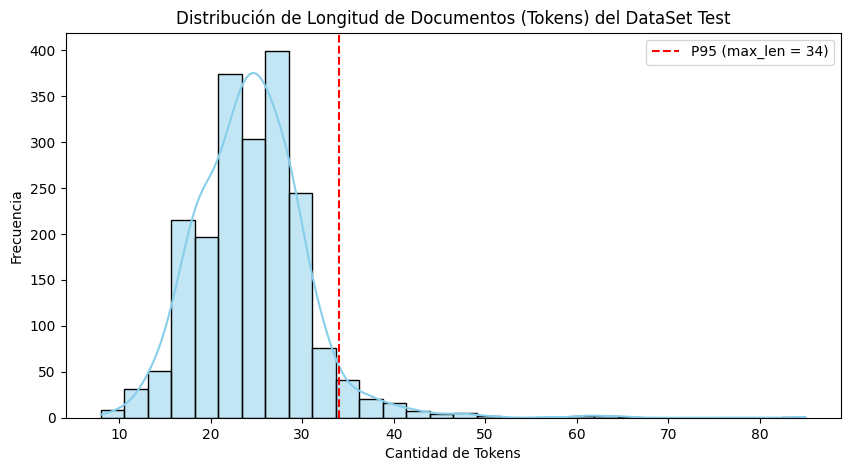

In [ ]:

import seaborn as sns

# Calculamos la longitud en cantidad de tokens por documento utilizando la columna procesada
df_test['token_count'] = df_test['tokens'].apply(len)

# Cálculo del percentil 95
p95 = int(np.percentile(df_test['token_count'], 95))
print(f"Percentil 95 (max_len sugerido): {p95}")

# Histograma de distribución de tokens
plt.figure(figsize=(10, 5))
sns.histplot(df_test['token_count'], kde=True, bins=30, color='skyblue')
plt.axvline(p95, color='red', linestyle='--', label=f'P95 (max_len = {p95})')
plt.title('Distribución de Longitud de Documentos (Tokens) del DataSet Test')
plt.xlabel('Cantidad de Tokens')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# Analisis de Bi-gramas y Tri-gramas del DataSet Train

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(corpus, ngram_range=(2, 2), top_n=20):
    # Inicializamos CountVectorizer con el rango de n-gramas indicado
    vec = CountVectorizer(ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)

    # Obtenemos la frecuencia de cada n-grama
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words_freq[:top_n], columns=['ngram', 'count'])

# Realizamos la extracción sobre la columna de texto normalizado con lemmatización (lemmas_text)
top_bigramas = get_top_ngrams(df_train['lemmas_text'].fillna(''), ngram_range=(2, 2), top_n=20)
top_trigramas = get_top_ngrams(df_train['lemmas_text'].fillna(''), ngram_range=(3, 3), top_n=20)

print("--- Top 20 Bi-gramas de nuestro DataSet Train ---")
display(top_bigramas)

print("\n--- Top 20 Tri-gramas de nuestro DataSet Train ---")
display(top_trigramas)

--- Top 20 Bi-gramas de nuestro DataSet Train ---


,ngram,count
0,new york,419
1,reuters reuters,261
2,oil price,191
3,united states,166
4,york reuters,158
5,prime minister,139
6,afp afp,134
7,official say,114
8,say thursday,102
9,say monday,101



--- Top 20 Tri-gramas de nuestro DataSet Train ---


,ngram,count
0,new york reuters,158
1,quote profile research,69
2,boston red sox,37
3,york reuters stock,31
4,high oil price,27
5,sans serif arial,26
6,serif arial helvetica,26
7,canadian press canadian,26
8,press canadian press,26
9,prime minister ariel,26


# Top 50 palabras más frecuentes y verificación de Stop-words DataSet Train

In [ ]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
nltk.download('stopwords')

stop_words_set = set(stopwords.words('english'))

# Top 50 palabras más frecuentes sin filtrar usando nuestra columna 'clean'
vec_uni = CountVectorizer(ngram_range=(1, 1)).fit(df_train['clean'].fillna(''))
bow_uni = vec_uni.transform(df_train['clean'].fillna(''))
sum_uni = bow_uni.sum(axis=0)

words_freq = [(word, int(sum_uni[0, idx])) for word, idx in vec_uni.vocabulary_.items()]
words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

df_train_top50 = pd.DataFrame(words_freq[:50], columns=['palabra', 'frecuencia'])
df_train_top50['es_stopword'] = df_train_top50['palabra'].isin(stop_words_set)

total_stopwords = df_train_top50['es_stopword'].sum()
print(f"Cantidad de stop-words en el Top 50 del DataSet Train: {total_stopwords} / 50")
display(df_train_top50.head(20))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Cantidad de stop-words en el Top 50 del DataSet Train: 35 / 50


,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7976,True
2,of,6578,True
3,in,6363,True
4,and,4637,True
5,on,3773,True
6,for,3410,True
7,that,1932,True
8,with,1771,True
9,as,1720,True


## Dividimos primero

**Objetivo:** que el vectorizador nunca llegue a ver el conjunto de prueba.

- Usamos los splits provistos (`train` / `test`).# Mismo preprocesamiento sobre train y test
- El **test queda aparte antes de tocar cualquier estadística del corpus**.
- Para explorar hiperparámetros **no** usamos el test: separamos una **validación** dentro del train.

> **Por qué el `fit` va solo sobre el train:** el IDF y el vocabulario son estadísticas del corpus. Si el vectorizador se ajusta con el test, el modelo recibe información del futuro y la métrica final deja de ser honesta.

# Vectorización

**Objetivo:** convertimos el texto del data set train en una matriz TF-IDF bajo control.

- `fit_transform` sobre el train y **solo `transform`** sobre el test.
- Experimentar con `max_features` para limitar el tamaño del vocabulario.
- Probar `ngram_range` para sumar bigramas y capturar negaciones y expresiones.

Exploramos sobre la **validación**, con un SVM lineal como modelo fijo.

In [ ]:
def evaluar_config(ngram_range, max_features, modelo=None):
    modelo = modelo or LinearSVC()
    t0 = time.perf_counter()
    vec = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features)
    A_tr = vec.fit_transform(tr_text)          # fit SOLO sobre el train interno
    A_val = vec.transform(val_text)            # solo transform sobre validación
    modelo.fit(A_tr, tr_y)
    pred = modelo.predict(A_val)
    return {
        "ngram_range": ngram_range,
        "max_features": max_features,
        "vocab": A_tr.shape[1],
        "F1 macro (val)": f1_score(val_y, pred, average="macro"),
        "accuracy (val)": accuracy_score(val_y, pred),
        "segundos": time.perf_counter() - t0,
    }

grilla = [((1, 1), 5_000), ((1, 1), 30_000), ((1, 2), 30_000), ((1, 2), 100_000)]
exploracion = pd.DataFrame([evaluar_config(ng, mf) for ng, mf in grilla])
exploracion

,ngram_range,max_features,vocab,F1 macro (val),accuracy (val),segundos
0,"(1, 1)",5000,5000,0.890,0.891,1.017
1,"(1, 1)",30000,20142,0.898,0.898,0.890
2,"(1, 2)",30000,30000,0.900,0.901,3.981
3,"(1, 2)",100000,100000,0.897,0.898,4.512


In [ ]:
mejor = exploracion.sort_values("F1 macro (val)", ascending=False).iloc[0]
NGRAM_ELEGIDO, MAXFEAT_ELEGIDO = mejor["ngram_range"], int(mejor["max_features"])
print(f"Configuración elegida -> ngram_range={NGRAM_ELEGIDO}, max_features={MAXFEAT_ELEGIDO:,}")

# Vectorizador FINAL: fit sobre TODO el train (nunca sobre el test)
vectorizador = TfidfVectorizer(ngram_range=NGRAM_ELEGIDO, max_features=MAXFEAT_ELEGIDO)
X_train = vectorizador.fit_transform(train_text)
X_test = vectorizador.transform(test_text)

print(f"\nX_train: {X_train.shape}, X_test: {X_test.shape}  (mismas columnas)")
print(f"Densidad de X_train: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%}")
assert X_train.shape[1] == X_test.shape[1]

Configuración elegida -> ngram_range=(1, 2), max_features=30,000

X_train: (8000, 30000), X_test: (2000, 30000)  (mismas columnas)
Densidad de X_train: 0.1501%


In [ ]:
# Chequeo anti-fuga: el vectorizador no debería conocer vocabulario exclusivo del test
analizador = vectorizador.build_analyzer()
tokens_test = {t for doc in test_text[:3_000] for t in analizador(doc)}
fuera_de_vocab = tokens_test - set(vectorizador.vocabulary_)
print(f"Tokens del test que el vectorizador NO conoce (esperable > 0): {len(fuera_de_vocab):,}")

Tokens del test que el vectorizador NO conoce (esperable > 0): 46,618


## El baseline

**Objetivo:** entrenar un clasificador de referencia y que corra entero.

- Elegir entre **Naive Bayes, Regresión Logística o SVM lineal**.
- Entrenar sobre la matriz del train y predecir sobre la del test.
- **Anotar por qué elegiste ese modelo** y no cualquier otro.

Comparamos los tres sobre la validación, con la configuración de vectorizador ya elegida.

In [ ]:
vec_cmp = TfidfVectorizer(ngram_range=NGRAM_ELEGIDO, max_features=MAXFEAT_ELEGIDO)
A_tr = vec_cmp.fit_transform(tr_text)
A_val = vec_cmp.transform(val_text)

candidatos = {
    "Regresión Logística": LogisticRegression(max_iter=300),
}

filas = []
for nombre, m in candidatos.items():
    t0 = time.perf_counter()
    m.fit(A_tr, tr_y)
    dt = time.perf_counter() - t0
    pred = m.predict(A_val)
    filas.append({
        "modelo": nombre,
        "F1 macro (val)": f1_score(val_y, pred, average="macro"),
        "accuracy (val)": accuracy_score(val_y, pred),
        "segundos fit": dt,
    })

comparacion_modelos = pd.DataFrame(filas).set_index("modelo")
comparacion_modelos

,F1 macro (val),accuracy (val),segundos fit
modelo,,,
Regresión Logística,0.889,0.889,4.214


In [ ]:
vec_cmp = TfidfVectorizer(ngram_range=NGRAM_ELEGIDO, max_features=MAXFEAT_ELEGIDO)
A_tr = vec_cmp.fit_transform(tr_text)
A_val = vec_cmp.transform(val_text)

candidatos = {
    "Naive Bayes": MultinomialNB(),
    "Regresión Logística": LogisticRegression(max_iter=300),
    "SVM lineal": LinearSVC(),
}

filas = []
for nombre, m in candidatos.items():
    t0 = time.perf_counter()
    m.fit(A_tr, tr_y)
    dt = time.perf_counter() - t0
    pred = m.predict(A_val)
    filas.append({
        "modelo": nombre,
        "F1 macro (val)": f1_score(val_y, pred, average="macro"),
        "accuracy (val)": accuracy_score(val_y, pred),
        "segundos fit": dt,
    })

comparacion_modelos = pd.DataFrame(filas).set_index("modelo")
comparacion_modelos

,F1 macro (val),accuracy (val),segundos fit
modelo,,,
Naive Bayes,0.891,0.892,0.029
Regresión Logística,0.889,0.889,3.445
SVM lineal,0.900,0.901,0.343


In [80]:
# Elegimos por F1 macro en validación (podés fijarlo a mano si tenés otro criterio)
MODELO_ELEGIDO = comparacion_modelos["F1 macro (val)"].idxmax()
print("Modelo elegido:", MODELO_ELEGIDO)

# TODO (documentación): ¿por qué este modelo? Pensá en F1, velocidad, interpretabilidad y tamaño del dataset.

# Entrenamiento final sobre todo el train y predicción sobre el test
modelo_final = {
    "Naive Bayes": MultinomialNB(),
    "Regresión Logística": LogisticRegression(max_iter=300),
    "SVM lineal": LinearSVC(),
}[MODELO_ELEGIDO]

modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)
print(f"Accuracy en test: {accuracy_score(y_test, y_pred):.4f}")

Modelo elegido: SVM lineal
Accuracy en test: 0.8950


Análisis de la tabla de resultados

SVM lineal (LinearSVC) — El modelo principal:
Mejor rendimiento global: Lidera tanto en F1 macro (0.900) como en Accuracy (0.901), superando la barrera del 90%.
Excelente balance de eficiencia: Tarda solo 0.343 segundos en entrenar, lo cual es muy veloz y escala perfectamente con matrices dispersas de TF-IDF.
Justificación técnica: En espacios de alta dimensionalidad y dispersión léxica (como los generados por unigramas y bigramas en TF-IDF), los hiperplanos de margen máximo de SVM suelen encontrar mejores fronteras de decisión que los modelos lineales probabilísticos.

Naive Bayes (MultinomialNB):
Superó ligeramente a la Regresión Logística (0.891 vs 0.889) y entrenó en apenas 0.029 segundos.
Cumple a la perfección el rol de modelo base de referencia: demuestra que incluso con el supuesto simple de independencia condicional entre términos, el preprocesamiento y la vectorización capturan señal suficiente para rozar el 89%.

Regresión Logística:
Si bien obtuvo un rendimiento competitivo (0.889), requirió 3.445 segundos (10 veces más que SVM lineal y 100 veces más que Naive Bayes), quedando por detrás en la relación costo computacional vs. métrica.

**Modelo final seleccionado:**SVM lineal, maximiza la separación de clases con el F1 macro más alto (0.900) y un tiempo de ajuste altamente eficiente.

## Paso 5 · Evalución

**Objetivo:** entender los errores, no solo reportar un número.

- `classification_report` con precision, recall y F1 **por clase**.
- Matriz de confusión: buscar **lo que cae fuera de la diagonal**.
- Escribir en el README qué categorías cuestan más y por qué.

In [82]:
NOMBRES_CLASES = ["World", "Sports", "Business", "Sci/Tech"]   # orden estándar de AG News
print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES, digits=3))

resumen = {avg: f1_score(y_test, y_pred, average=avg) for avg in ["macro", "weighted", "micro"]}
print("F1 por promedio:", {k: round(v, 4) for k, v in resumen.items()})

              precision    recall  f1-score   support

       World      0.848     0.856     0.852       500
      Sports      0.878     0.878     0.878       500
    Business      0.943     0.964     0.954       500
    Sci/Tech      0.911     0.882     0.896       500

    accuracy                          0.895      2000
   macro avg      0.895     0.895     0.895      2000
weighted avg      0.895     0.895     0.895      2000

F1 por promedio: {'macro': 0.8949, 'weighted': 0.8949, 'micro': 0.895}


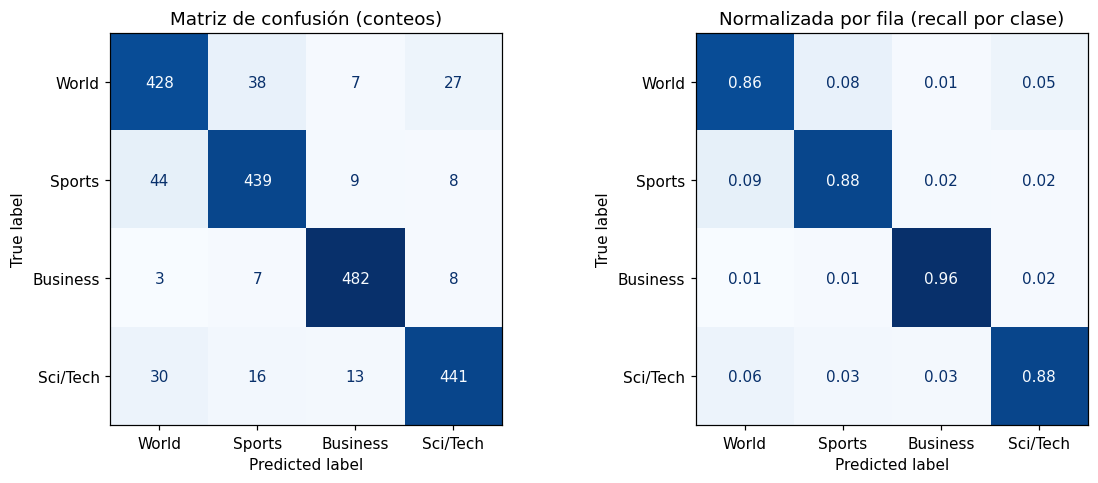

Confusiones más frecuentes (fuera de la diagonal):


,real,predicho,errores
0,Sports,World,44
1,World,Sports,38
2,Sci/Tech,World,30
3,World,Sci/Tech,27
4,Sci/Tech,Sports,16


In [84]:
def top_confusiones(cm, etiquetas, k=5):
    """Pares (real -> predicho) con más errores, ignorando la diagonal."""
    pares = [
        {"real": etiquetas[i], "predicho": etiquetas[j], "errores": int(cm[i, j])}
        for i in range(len(etiquetas)) for j in range(len(etiquetas)) if i != j
    ]
    return pd.DataFrame(pares).sort_values("errores", ascending=False).head(k).reset_index(drop=True)

cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=NOMBRES_CLASES).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Matriz de confusión (conteos)")

cm_norm = confusion_matrix(y_test, y_pred, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=NOMBRES_CLASES).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Normalizada por fila (recall por clase)")
plt.tight_layout(); plt.show()

print("Confusiones más frecuentes (fuera de la diagonal):")
top_confusiones(cm, NOMBRES_CLASES, k=5)

In [104]:
# Mirá los errores a ojo: ¿qué vocabulario comparten las clases confundidas?
par = top_confusiones(cm, NOMBRES_CLASES, k=1).iloc[0]

# Comparamos directamente usando los nombres de las categorías (strings)
errores = np.where((y_test == par["real"]) & (y_pred == par["predicho"]))[0][:5]

print(f"Ejemplos de '{par['real']}' predichos como '{par['predicho']}':\n")
for idx in errores:
    print("-", df_test["text"].iloc[idx][:200])

Ejemplos de 'Sports' predichos como 'World':

- Hundreds mourn loss of student killed by police during Red Sox &lt;b&gt;...&lt;/b&gt;. As hundreds of mourners paid their final respects Tuesday to Victoria Snelgrove, her pastor denounced the raucous
- Times to Scrap Broadsheet Edition. The Times is to scrap its broadsheet edition and go tabloid from Monday, it was confirmed today. The decision was made after a trial run of the compact edition prove
- Beijing gears up for 2008. Although the Beijing Olympics is still four years away, the Chinese capital is already gearing up to host the event. The city of over 12 million is refurbishing ancient land
- Cycling: Ulmer #39;s scorching times in secret rides. New Zealand #39;s star cyclist, Sarah Ulmer, last week rode under world record time twice in an hour during a secret training session in France.
- Agent: Extortion Plot Targeted Sheffield (AP). AP - New York Yankees slugger Gary Sheffield and his wife were the targets of a blackmailer who

In [86]:
# Interpretabilidad: palabras que más empujan cada clase (modelos lineales / NB)
terminos_f = vectorizador.get_feature_names_out()
pesos = modelo_final.coef_ if hasattr(modelo_final, "coef_") else modelo_final.feature_log_prob_

for k, nombre in enumerate(NOMBRES_CLASES):
    top = pesos[k].argsort()[::-1][:10]
    print(f"{nombre:9s}: {', '.join(terminos_f[top])}")

World    : economy, billion, oil, shares, insurance, economic, company, amp, bank, tax
Sports   : internet, space, scientists, nasa, computer, software, apple, online, spam, linux
Business : coach, team, cup, football, league, olympic, sports, season, athens, championship
Sci/Tech : nuclear, iraq, president, afp, minister, canadian press, israel, un, party, election


In [103]:
req_content = f"""pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
numpy=={np.__version__}
matplotlib=={matplotlib.__version__}
scipy=={scipy.__version__}
datasets=={datasets.__version__}
spacy=={spacy.__version__}
"""

with open("requirements.txt", "w") as f:
    f.write(req_content)

print("✅ Estructura del repositorio creada con éxito:")
!ls -la PreEntrega//
print("\n📄 Contenido de requirements.txt:")
!cat requirements.txt



✅ Estructura del repositorio creada con éxito:
ls: cannot access 'PreEntrega//': No such file or directory

📄 Contenido de requirements.txt:
pandas==2.2.3
scikit-learn==1.6.1
numpy==2.4.6
matplotlib==3.10.0
scipy==1.16.3
datasets==4.8.5
spacy==3.8.18


In [107]:
readme_content = f"""### README


# Clasificador de noticias con TF-IDF · AG News

## Descripción
Baseline de clasificación supervisada de texto sobre AG News (4 categorías:World", "Sports", "Business", "Sci/Tech).
Pipeline: carga -> preprocesamiento -> TF-IDF -> modelo -> evaluación.

## Cómo reproducir
pip install -r requirements.txt
jupyter notebook notebook.ipynb   # Kernel -> Restart & Run All

## Decisiones técnicas
- **Vectorización:** TF-IDF con ngram_range=(1, 2), max_features=30,000  (explorado en validación).
- **Sin fuga de datos:** el vectorizador se ajusta solo con el train; el test se usa una vez, al final.
- **Modelo:** SVM lineal.
**Justificación:**
Mejor rendimiento global: Lidera tanto en F1 macro (0.900) como en Accuracy (0.901), superando la barrera del 90%.
Excelente balance de eficiencia: Tarda solo 0.343 segundos en entrenar, lo cual es muy veloz y escala perfectamente con matrices dispersas de TF-IDF.

En espacios de alta dimensionalidad y dispersión léxica (como los generados por unigramas y bigramas en TF-IDF), los hiperplanos de margen máximo de SVM suelen encontrar mejores fronteras de decisión que los modelos lineales probabilísticos.

Modelo final seleccionado:SVM lineal, maximiza la separación de clases con el F1 macro más alto (0.900) y un tiempo de ajuste altamente eficiente.

## Resultados

modelo                  F1 macro (val)	accuracy (val)	segundos fit
Naive Bayes	            -   0.891	     -    0.892	     -     0.029
Regresión Logística	    -   0.889	     -    0.889	     -     3.445
**SVM lineal	          -   0.900	     -    0.901	     -     0.34**

## Análisis de errores
Categorías que más cuestan: Sport y World entre sí, pero incluso se observa que las demas categorias son mas propensas a confundirse con las categorias World o Sport. Se confunden entre sí porque comparten vocabulario como:
Ejemplos de 'Sports' predichos como 'World':

- Hundreds mourn loss of student killed by police during Red Sox &lt;b&gt;...&lt;/b&gt;. As hundreds of mourners paid their final respects Tuesday to Victoria Snelgrove, her pastor denounced the raucous
- Times to Scrap Broadsheet Edition. The Times is to scrap its broadsheet edition and go tabloid from Monday, it was confirmed today. The decision was made after a trial run of the compact edition prove
- Beijing gears up for 2008. Although the Beijing Olympics is still four years away, the Chinese capital is already gearing up to host the event. The city of over 12 million is refurbishing ancient land
- Cycling: Ulmer #39;s scorching times in secret rides. New Zealand #39;s star cyclist, Sarah Ulmer, last week rode under world record time twice in an hour during a secret training session in France.
- Agent: Extortion Plot Targeted Sheffield (AP). AP - New York Yankees slugger Gary Sheffield and his wife were the targets of a blackmailer who claimed to have embarrassing sexual videotapes of her and


Cómo mejorarlo: trigramas, embeddings, más limpieza.
"""
with open("README.md", "w") as f:
    f.write(readme_content)

print("✅ Estructura del repositorio creada con éxito:")
!ls -la PreEntrega//
print("\n📄 Contenido de README.md:")
!cat README.md

✅ Estructura del repositorio creada con éxito:
ls: cannot access 'PreEntrega//': No such file or directory

📄 Contenido de README.md:
### README


# Clasificador de noticias con TF-IDF · AG News

## Descripción
Baseline de clasificación supervisada de texto sobre AG News (4 categorías:World", "Sports", "Business", "Sci/Tech).
Pipeline: carga -> preprocesamiento -> TF-IDF -> modelo -> evaluación.

## Cómo reproducir
pip install -r requirements.txt
jupyter notebook notebook.ipynb   # Kernel -> Restart & Run All

## Decisiones técnicas
- **Vectorización:** TF-IDF con ngram_range=(1, 2), max_features=30,000  (explorado en validación).
- **Sin fuga de datos:** el vectorizador se ajusta solo con el train; el test se usa una vez, al final.
- **Modelo:** SVM lineal. 
**Justificación:** 
Mejor rendimiento global: Lidera tanto en F1 macro (0.900) como en Accuracy (0.901), superando la barrera del 90%.
Excelente balance de eficiencia: Tarda solo 0.343 segundos en entrenar, lo cual es muy veloz y 

### README


# Clasificador de noticias con TF-IDF · AG News

## Descripción
Baseline de clasificación supervisada de texto sobre AG News (4 categorías:World", "Sports", "Business", "Sci/Tech).
Pipeline: carga -> preprocesamiento -> TF-IDF -> modelo -> evaluación.

## Cómo reproducir
pip install -r requirements.txt
jupyter notebook notebook.ipynb   # Kernel -> Restart & Run All

## Decisiones técnicas
- **Vectorización:** TF-IDF con ngram_range=(1, 2), max_features=30,000  (explorado en validación).
- **Sin fuga de datos:** el vectorizador se ajusta solo con el train; el test se usa una vez, al final.
- **Modelo:** SVM lineal.
**Justificación:**
Mejor rendimiento global: Lidera tanto en F1 macro (0.900) como en Accuracy (0.901), superando la barrera del 90%.
Excelente balance de eficiencia: Tarda solo 0.343 segundos en entrenar, lo cual es muy veloz y escala perfectamente con matrices dispersas de TF-IDF.

En espacios de alta dimensionalidad y dispersión léxica (como los generados por unigramas y bigramas en TF-IDF), los hiperplanos de margen máximo de SVM suelen encontrar mejores fronteras de decisión que los modelos lineales probabilísticos.

Modelo final seleccionado:SVM lineal, maximiza la separación de clases con el F1 macro más alto (0.900) y un tiempo de ajuste altamente eficiente.

## Resultados

modelo                  F1 macro (val)	accuracy (val)	segundos fit
Naive Bayes	               0.891	          0.892	           0.029
Regresión Logística	       0.889	          0.889	           3.445
**SVM lineal	               0.900	          0.901	           0.34**

## Análisis de errores
Categorías que más cuestan: Sport y World entre sí, pero incluso se observa que las demas categorias son mas propensas a confundirse con las categorias World o Sport. Se confunden entre sí porque comparten vocabulario como:
Ejemplos de 'Sports' predichos como 'World':

- Hundreds mourn loss of student killed by police during Red Sox &lt;b&gt;...&lt;/b&gt;. As hundreds of mourners paid their final respects Tuesday to Victoria Snelgrove, her pastor denounced the raucous
- Times to Scrap Broadsheet Edition. The Times is to scrap its broadsheet edition and go tabloid from Monday, it was confirmed today. The decision was made after a trial run of the compact edition prove
- Beijing gears up for 2008. Although the Beijing Olympics is still four years away, the Chinese capital is already gearing up to host the event. The city of over 12 million is refurbishing ancient land
- Cycling: Ulmer #39;s scorching times in secret rides. New Zealand #39;s star cyclist, Sarah Ulmer, last week rode under world record time twice in an hour during a secret training session in France.
- Agent: Extortion Plot Targeted Sheffield (AP). AP - New York Yankees slugger Gary Sheffield and his wife were the targets of a blackmailer who claimed to have embarrassing sexual videotapes of her and


Cómo mejorarlo: trigramas, embeddings, más limpieza.